In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy
import math
import os
import sys
sys.path.insert(1, '../')

from params import p_cosmology
from transient_rates import R_CC, R_TDE, R_sGRB_gaus, plot_rates

import astropy.units as u
import astropy.cosmology as acosmo

### Volumetric rates
We take different volumetric rates per transient types to compare them.
<br>
It seems that the papers I have are from  before Gw170817, so I wonder if the KN / sGRB rates have been corrected since. 

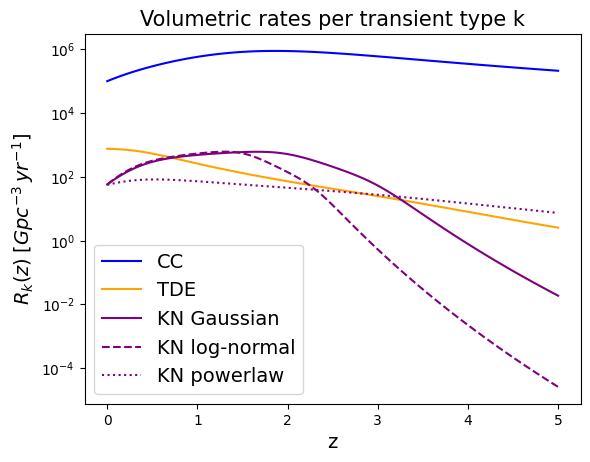

In [2]:
plot_rates()

### Computing $L_k$

Following Jannis' PhD thesis, if we assume the neutrino emission of the population follows a single-powerlaw of index $\gamma$, then the total contribution to the diffuse flux would be given by
$$
\frac{dN}{dAdtdE} = \int (1+z)^{2-\gamma}\frac{\phi_0^k T' R_k(z)}{4\pi D_L^2(z)}\bigg(\frac{E}{E_0}\bigg)^\gamma \frac{dV_c}{dz}dz = \lambda_k\phi_\nu (E)\;[\text{GeV}^{-1}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]
$$

Where the intrinisic luminosity $L_k$ will be given by:
$$
L_k(E) = \phi_0^k\bigg(\frac{E}{E_0}\bigg)^\gamma
$$

We can start by assuming the best-fit single power law model for the diffuse neutrino flux of 
$$
\gamma=-2.52\pm0.04
$$ 
$$\phi_{100\,TeV}^{\nu+\bar \nu} = 1.80^{+0.13}_{-0.16}\;[10^{-18}\text{GeV}^{-1}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]
$$
Which means that the nmormalization factor can be obtained from:
$$
\phi_0^k = \frac{\lambda_k\phi_0 (E/E_0)^{\gamma}}{\int (1+z)^{2-\gamma}\frac{T_k' R_k(z)}{4\pi D_L^2(z)}\big(\frac{E}{E_0}\big)^\gamma \frac{dV_c}{dz}dz}
$$

One issue is that even if I  choose that the transient population to have the same power-law index as the diffuse  flux, the redshift distribution will chane the powerlaw output. Therefore, $\phi_0^k$ will not be a constant, but rather a quantity from energy. I can do two things:
* Compute it at the energy of the neutrino alert $\phi_0^k(E_\nu)$
* Compute an average $\bar \phi_0^k$ over a range of energies,  see  hos much it  changes.
  
I will  test both. 

In [3]:
def diffuse_nu_spl(E, gamma=-2.52, phi_0=1.80):
    '''
    Best fit for the measured IceCube diffuse neutrino flux using the single-powerlaw.

    Params
    ------
    E: array, GeV. Energy of the neutrinos
    gamma: float. Poweerlaw index
    phi_0: float, powerlaw normalization in [10^-18 / GeV / cm^2 / s / sr]

    Returns
    -------
    phi_nu: arrray. Neutrino diffuse flux dN/dEdAdt in [ N / GeV / cm^2 / s / sr]
    '''
    E_0 = 1e5 #if E in GeV
    phi_nu = phi_0 * 1e-18 * (E / E_0) ** gamma
    return phi_nu

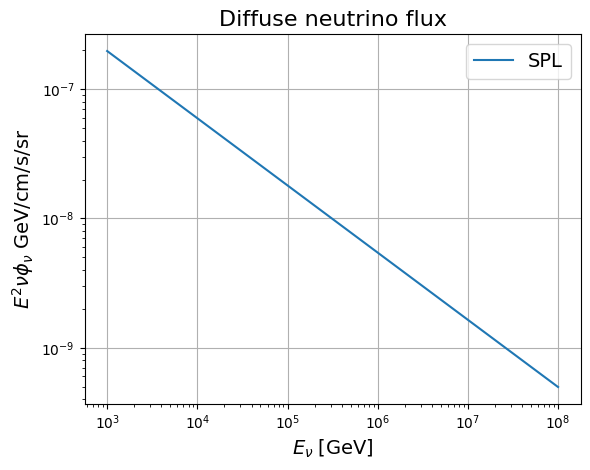

In [4]:
E_range = np.logspace(3, 8, 1000) #in GeV
diff_nu_E2 = diffuse_nu_spl(E_range) * E_range ** 2

plt.plot(E_range, diff_nu_E2, label='SPL')
plt.loglog()
plt.xlabel(r'$E_\nu\;[\text{GeV}]$',  fontsize=14)
plt.ylabel(r'$E^2\nu\phi_\nu\;\text{GeV}/\text{cm}/\text{s}/\text{sr}$', fontsize=14)
plt.title('Diffuse neutrino flux', fontsize=16)
plt.legend(fontsize=14)
plt.grid()
plt.show()

From the Firesong code:

$$ \Phi_{z=1}^{PS} = \frac{4 \pi \Phi_\mathrm{diffuse}}
        {N_\mathrm{tot}\,d_L^2(z=1)\, \int_0^{10}
        \frac{ (1+z)^{-\gamma+2} }{d_L(z)^2}
        \frac{\frac{\mathrm{d}N}{\mathrm{d}z} V_c(z)}
        { \int_0^{z_\mathrm{max}} \frac{\mathrm{d}N}{\mathrm{d}z'}
        V_c(z') \,\mathrm{d}z'} \,\mathrm{d}z} $$

$$ \Phi_{z=1}^{PS} = \frac{4 \pi \Phi_\mathrm{diffuse}}
        {N_\mathrm{tot}\,d_L^2(z=1)\, \int_0^{10}
        \frac{ (1+z)^{-\gamma+2} }{d_L(z)^2}
        \frac{\frac{\mathrm{d}N}{\mathrm{d}z} V_c(z)}
        { \int_0^{z_\mathrm{max}} \frac{\mathrm{d}N}{\mathrm{d}z'}
        V_c(z') \,\mathrm{d}z'} \,\mathrm{d}z} $$

In [11]:
def get_phi_0_k_firesong(R_z, z=1, z_max=10, phi_diff=1.8e-18, p=p_cosmology, gamma_k=-2.13):
    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
    

def  get_phi_0_k(R_z, E_nu, lambda_k, T_k, R0=1, p=p_cosmology, z_max=6, gamma_k=-2.52):
    '''
    Estimate the intrinsic source luminosity from a contribution of the total diffuse neutrino flux

    Params:
    ------
    R_z: func. Volumetric  rate evolution chosen for a specific source  class.
    E_nu: float, GeV. Reconstructed energy of the  neutrino as publshed in the alert.
    lambda_k: float. Fractional  ontribution of the diffuse neutrino flux. lambda_k=0.1 means we assume that all sources of type k 
        contribute  10%  of the observed diffuse flux at an energy  of E_nu
    T_k: float, duration of transient k in days
    R0:  float. Volumetric rate  of  transient oftypee k at z ~ 0  in Mpc^-3 yr^-1
    gamma_k: float. Powerlaw index for thee  population flux. Assumed  to be same as SPL fit for IC diffuse flux.
    

    '''
    if not isinstance(T_k, u.quantity.Quantity):
        T_k = T_k * u.d #we add  the days units. 
    
    
    #get comologicalmodel
    cosmo = acosmo.LambdaCDM(H0=p['h0']* u.km / u.s / u.Mpc, 
                         Om0= p['omega_M'],
                        Ode0=p['omega_L'])#, Tcmb0=2.725 * u.K, 
    
    #ingtegration limit
    z_range = np.linspace(p['z_min'], z_max, p['N_int_steps'])
    

    
    diff_nu_flux = diffuse_nu_spl(E_nu) * u.GeV ** -1 * u.s ** -1 * u.sr ** -1 * u.cm ** -2

    

    #integral
    D_L = cosmo.luminosity_distance(z_range).to(u.cm)
    dVdz =  cosmo.differential_comoving_volume(z_range)
    # print('dVdz: ', dVdz)
    R_k =  R_z(z_range, R0=R0).to(u.s ** -1 * u.Mpc ** -3)
    print('R_k * dVdz: ',  R_k *dVdz)
    y = (1 + z_range) ** (3 - gamma_k) * T_k.to('s') / (4 * np.pi *  D_L ** 2) * R_k * dVdz  
    
    E_range = np.logspace(4, 7, 1000)
    phi_0_k_E_range = lambda_k * diff_nu_flux / scipy.integrate.trapezoid(y, z_range) * (E_range / 1e5) ** gamma_k

    
    phi_0_k = scipy.interpolate.interp1d(E_range, phi_0_k_E_range)(E_nu)

    return phi_0_k
    
    

    
    
def L_k_old(lambda_k, nu_flux, R_z, R0=1, p=p_cosmology, z_max=6):

    #get comologicalmodel
    cosmo = acosmo.LambdaCDM(H0=67.4 * u.km / u.s / u.Mpc, 
                         Om0=0.315,
                        Ode0=0.685)#, Tcmb0=2.725 * u.K, 

    z_range = np.linspace(p['z_min'], z_max, p['N_int_steps'])

    D_L = cosmo.luminosity_distance(z_range)
    dVdz =  cosmo.differential_comoving_volume(z_range)
    y = 1 / (4 * np.pi *  D_L** 2) * R_z(z_range, R0=R0) / (1 + z_range)  * dVdz

    nu_flux = nu_flux * u.Mpc ** -2 * u.yr ** -1 * u.sr **  -1

    return lambda_k * nu_flux * 4 * np.pi / scipy.integrate.trapezoid(y, z_range)

In [12]:
R0 = p_cosmology['R0']
L_CC_100 = get_phi_0_k(R_CC, 1e5, 0.1, 40, R0=R0['SN CC'], gamma_k=-2)
L_Ibc_100 = get_phi_0_k(R_CC, 1e5, 0.1, 15, R0=R0['SN CC'] * 0.25, gamma_k=-2)
L_II_100 = get_phi_0_k(R_CC, 1e5, 0.1, 100, R0=R0['SN CC'] * 0.75, gamma_k=-2)
L_TDE_100 = get_phi_0_k(R_TDE, 1e5, 0.1, 365, R0=R0['TDE'], gamma_k=-2)
L_KN_100 = get_phi_0_k(R_sGRB_gaus, 1e5, 0.1, 10, R0=R0['KN'], gamma_k=-2)

print('CC: ', L_CC_100)
print('Ibc: ', L_Ibc_100)
print('II: ', L_II_100)
print("TDE: ", L_TDE_100)
print('KN: ', L_KN_100)

R_k * dVdz:  [2.80969430e-09 1.14334656e-03 4.98317038e-03 1.21023762e-02
 2.30115143e-02 3.81333999e-02 5.77931026e-02 8.22122308e-02
 1.11506356e-01 1.45684553e-01 1.84650270e-01 2.28203088e-01
 2.76041179e-01 3.27764627e-01 3.82879915e-01 4.40806083e-01
 5.00883062e-01 5.62382671e-01 6.24522585e-01 6.86483374e-01
 7.47428381e-01 8.06525852e-01 8.62972430e-01 9.16016790e-01
 9.64982055e-01 1.00928558e+00 1.04845484e+00 1.08213833e+00
 1.11011108e+00 1.13227433e+00 1.14864998e+00 1.15937034e+00
 1.16466425e+00 1.16484077e+00 1.16027161e+00 1.15137345e+00
 1.13859106e+00 1.12238196e+00 1.10320318e+00 1.08150026e+00
 1.05769855e+00 1.03219688e+00 1.00536321e+00 9.77532063e-01
 9.49003524e-01 9.20043332e-01 8.90883960e-01 8.61726319e-01
 8.32741912e-01 8.04075257e-01 7.75846423e-01 7.48153587e-01
 7.21075528e-01 6.94673987e-01 6.68995886e-01 6.44075350e-01
 6.19935558e-01 5.96590392e-01 5.74045910e-01 5.52301647e-01
 5.31351744e-01 5.11185943e-01 4.91790438e-01 4.73148614e-01
 4.55241666

### Test to see what I get back
If I assume $\gamma_k=-2.52$ and $\phi_0=?$, I can see how far off I'm from the diffuse flux. In other  words, what value makes sense for $\phi_0$.

In [15]:
def nu_flux_CC(E, gamma=-2.52, phi_0=1e50):

    return phi_0 * (E  / 1e5) ** gamma
    
def total_nu_flux_k(R_z, E, gamma_k=-2.52, phi_0=1e50, T_k=40, R0=1, E0=1e5, z_max=6, p=p_cosmology):

    #get comologicalmodel
    cosmo = acosmo.LambdaCDM(H0=67.4 * u.km / u.s / u.Mpc, 
                         Om0=0.315,
                        Ode0=0.685)#, Tcmb0=2.725 * u.K, 

    z_range = np.linspace(p['z_min'], z_max, p['N_int_steps'])

    D_L = cosmo.luminosity_distance(z_range)
    dVdz =  cosmo.differential_comoving_volume(z_range)

    #get units right!
    T_k = (T_k * u.d).to(u.s)
    phi_0 = phi_0 * u.GeV**-1 * u.s**-1 
    R_k =  R_z(z_range, R0=R0).to(u.s ** -1 * u.Mpc ** -3)
    D_L = D_L.to(u.cm)

    
    
    y = (1+z_range) ** (2 - gamma_k) * phi_0 * T_k / (4 * np.pi *  D_L** 2) * R_k * (E / E0)  ** gamma_k * dVdz

    dN_dEdtdA = scipy.integrate.trapezoid(y, z_range)
    return dN_dEdtdA
    

In [16]:
E_range = np.logspace(3, 8, 100) #in GeV
diff_nu = diffuse_nu_spl(E_range) 
E_nu = 1e5

phi_0_cc = get_phi_0_k(R_CC, E_nu, 0.1, 40, R0=R0['SN CC'])
cc_nu = [total_nu_flux_k(R_CC, E, phi_0=phi_0_cc, T_k=40, R0=R0['SN CC']).value for E in E_range]

phi_0_TDE = get_phi_0_k(R_TDE, E_nu, 0.1, 365, R0=R0['TDE'])
TDE_nu = [total_nu_flux_k(R_TDE, E, phi_0=phi_0_TDE, T_k=365, R0=R0['TDE']).value for E in E_range]

phi_0_KN = get_phi_0_k(R_sGRB_gaus, E_nu, 0.1, 10, R0=R0['KN'])
KN_nu = [total_nu_flux_k(R_sGRB_gaus, E, phi_0=phi_0_KN, T_k=10, R0=R0['KN']).value for E in E_range]



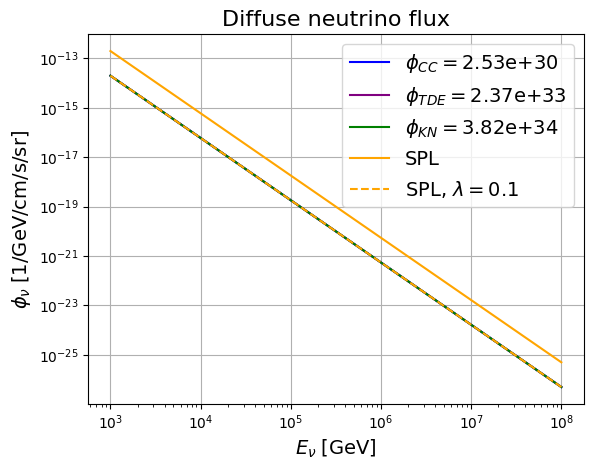

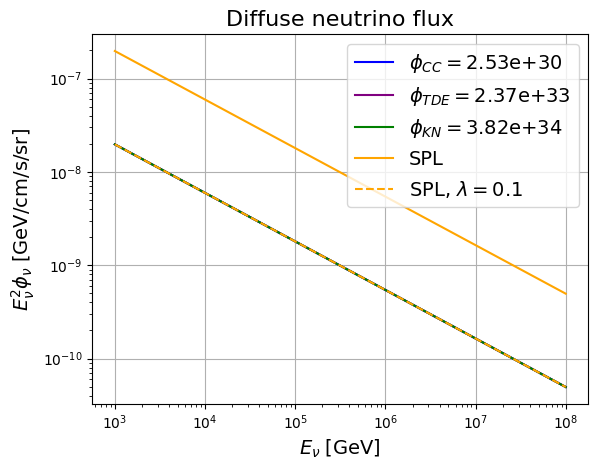

In [17]:
plt.plot(E_range, cc_nu, label=r'$\phi_{CC}=$'+f'{np.format_float_scientific(phi_0_cc, precision=2)}', c='blue')
plt.plot(E_range, TDE_nu, label=r'$\phi_{TDE}=$'+f'{np.format_float_scientific(phi_0_TDE, precision=2)}', c='purple')
plt.plot(E_range, KN_nu, label=r'$\phi_{KN}=$'+f'{np.format_float_scientific(phi_0_KN, precision=2)}', c='green')


plt.plot(E_range, diff_nu, label='SPL', c='orange')
plt.plot(E_range, 0.1 * diff_nu, label=r'SPL, $\lambda=0.1$', c='orange', linestyle='dashed')


plt.loglog()
plt.xlabel(r'$E_\nu\;[\text{GeV}]$',  fontsize=14)
plt.ylabel(r'$\phi_\nu\;[1 /\text{GeV}/\text{cm}/\text{s}/\text{sr}]$', fontsize=14)
plt.title('Diffuse neutrino flux', fontsize=16)
plt.legend(fontsize=14)
plt.grid()
plt.show()


#E^2 plot


plt.plot(E_range, cc_nu * E_range**2, label=r'$\phi_{CC}=$'+f'{np.format_float_scientific(phi_0_cc, precision=2)}', c='blue')
plt.plot(E_range, TDE_nu * E_range**2, label=r'$\phi_{TDE}=$'+f'{np.format_float_scientific(phi_0_TDE, precision=2)}', c='purple')
plt.plot(E_range, KN_nu * E_range**2, label=r'$\phi_{KN}=$'+f'{np.format_float_scientific(phi_0_KN, precision=2)}', c='green')


plt.plot(E_range, diff_nu * E_range**2, label='SPL', c='orange')
plt.plot(E_range, 0.1 * diff_nu * E_range**2, label=r'SPL, $\lambda=0.1$', c='orange', linestyle='dashed')


plt.loglog()
plt.xlabel(r'$E_\nu\;[\text{GeV}]$',  fontsize=14)
plt.ylabel(r'$E_\nu^2\phi_\nu\;[\text{GeV}/\text{cm}/\text{s}/\text{sr}]$', fontsize=14)
plt.title('Diffuse neutrino flux', fontsize=16)
plt.legend(fontsize=14)
plt.grid()
plt.show()


### Test
I don't understand why the total contribution does not show the features of R(z) and instead just shows it as a single powerlaw. I can maybe device a test where we test a flat R(z) and a really steep one, and see if the final spectrum changes. 
TO DO:
* Maybe get an average $\phi_0$ by re-computing  it for different input energies
* Write down the Rubin counterpart search document to obtain this.

In [ ]:
nu_flux = 2.43e50
params['N_int_steps'] = int(1e5)
L_CC = L_k(0.1, nu_flux, R_CC, R0=R0['SN CC'], z_max=10, p=params)
L_TDE = L_k(0.1, nu_flux, R_TDE, R0=R0['TDE'],  z_max=10, p=params)
L_KN = L_k(0.1, nu_flux, R_sGRB_gaus, R0=R0['KN'], z_max=10, p=params)
print("L_CC * T_CC: ", L_CC)
print("L_TDE * T_TDE: ", L_TDE)
print("L_KN * T_KN: ", L_KN)

print("Then,  dividing by the transient  duration:" )
print("L_CC = ", L_CC / (40 * 24 * 3600), ' 100 TeV / s = ',  L_CC / (40 * 24 * 3600) * 1.602,  ' erg / s')
print("L_TDE = ", L_TDE /(365 * 24 * 3600), ' 100 TeV / s = ',  L_TDE / (365 * 24 * 3600) * 1.602,  ' erg / s')
print("L_KN = ", L_KN /(10 * 24 * 3600), ' 100 TeV / s = ',  L_KN/ (10 * 24 * 3600) * 1.602,  ' erg / s')

In [ ]:
plt.plot(z_range, R_CC(z_range), label=r'$R_{cc}$ from Madau & Dickinson 2014')
plt.plot(z_range, R_TDE(z_range), label=r'$R_{TDE}$ from Sun++2015')
plt.xlabel('z', fontsize=14)
plt.ylabel(r'$R_k(z)\;[\text{Mpc}^{-3}\,\text{yr}^{-1}]$', fontsize=14)
plt.yscale('log')
plt.show()

In [ ]:
L_CC / (4 * np.pi * cosmo.luminosity_distance(1).to('cm') ** 2) * 1e4 *  u.cm  ** 2

In [ ]:
cosmo = acosmo.LambdaCDM(H0=67.4 * u.km / u.s / u.Mpc, 
                         Om0=0.315,
                        Ode0=0.685)#, Tcmb0=2.725 * u.K, 


D_L = cosmo.luminosity_distance(0.1)

In [ ]:
D_L

<Quantity 477.5220941 Mpc>

In [ ]:
t_max =10**7.5 * u.s
t_min = 10**4.5 * u.s
print(t_max.to(u.d))
print(t_min.to(u.d))

366.0043588157846 d
0.36600435881578464 d
